#  PEC with SLC

[Probabilistic error cancellation (PEC)](https://arxiv.org/pdf/1612.02058) is a technique for mitigating quantum noise in observable expectation value calculations. It lets you compute an unbiased estimate of the expectation values. This technique works by executing an ensemble of noisy circuits injected with the inverse of a learned noise model. The noise model is then approximated to a Pauli channel by using Pauli twirling (also known as [randomized compiling](https://journals.aps.org/pra/abstract/10.1103/PhysRevA.94.052325)). Such noise models can be learned efficiently and can be mitigated by using PEC (see [Probabilistic error cancellation with sparse Pauli-Lindblad models on noisy quantum
processors](https://arxiv.org/pdf/2201.09866) for more details).

PEC requires exponential shot overhead to compute an unbiased estimate. [Shaded Lightcones (SLC)](https://arxiv.org/abs/2409.04401) is a technique that uses classical resources to bound the sensitivity to errors throughout the circuit. Using these bounds, the user can controllably tune the bias in the observable estimation.

<img src="../images/pec_with_slc.png" width="300"/>

This guide shows how to use PEC combined with SLC to mitigate gate noise with reduced shot overhead compared to vanilla PEC.

The workflow follows:
1. Specify a circuit and observable.
2. Compute noisy, unmitigated expectation values.
3. Compute forward and backward bounds on the bias.
4. Learn the entangling layers' noise by using qiskit-noise-learning.
5. Use the learned noise to merge the computed bounds into a local scales matrix.
6. Choose the desired bias bound based on the shot overhead-bias trade-off.
7. Prepare a PEC + SLC program, execute the program, and post-process.
8. Compare the mitigated expectation values and shot overhead.

### Specify a circuit and observable

Prepare a mirror circuit of a Trotterized time evolution of a 1D Ising chain Hamiltonian on eight qubits. Mirror the circuit to cancel its unitary and form an identity circuit, so each observable's ideal expectation value is known to be 1 without the need to compute it. In addition, mirroring doubles the circuit depth, which in turn doubles the noise's effect.

Use the angle $\theta= \frac{\pi}{4}$ to make the dynamics non-Clifford.

Visualization of 1 mirrored Trotter step


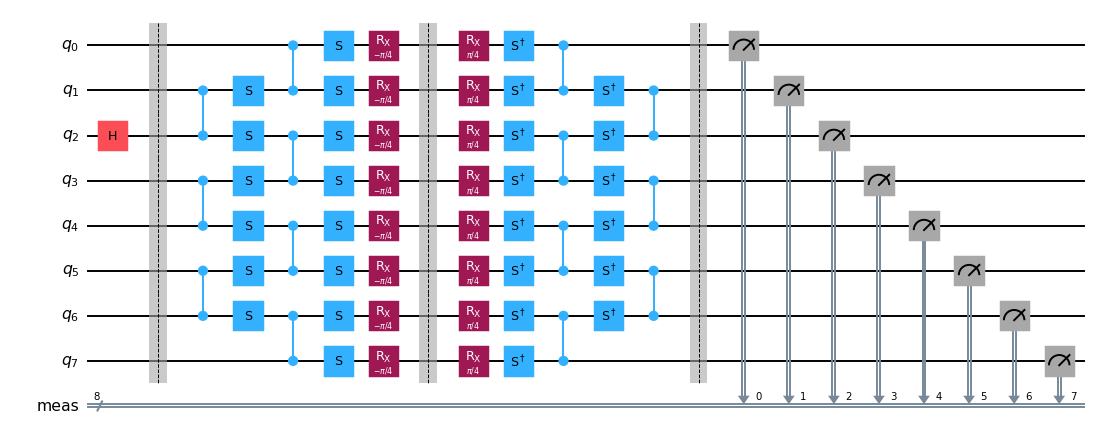

In [1]:
import warnings

import numpy as np
from qiskit.circuit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_mitigation.utils import get_measurement_bases

warnings.filterwarnings("ignore")


def construct_ising_circuit(
    num_qubits: int,
    num_trotter_steps: int,
    rx_angle: float,
) -> QuantumCircuit:
    circuit = QuantumCircuit(num_qubits)

    for _ in range(num_trotter_steps):
        circuit.rx(rx_angle, range(num_qubits))
        for first_qubit in (1, 2):
            for idx in range(first_qubit, num_qubits, 2):
                # equivalent to Rzz(-pi/2):
                circuit.sdg([idx - 1, idx])
                circuit.cz(idx - 1, idx)

    return circuit


def prepare_basis(circuit: QuantumCircuit, basis: list[int]) -> QuantumCircuit:
    # basis is a list of integer values from 0 to 3. These map to the basis measurement as:
    # 0 = I; 1 = Z; 2 = X; 3 = Y
    assert len(basis) == circuit.num_qubits

    out_circ = circuit.copy_empty_like()
    for qb, bas in enumerate(basis):
        if bas == 2:
            out_circ.h(qb)
        elif bas == 3:
            out_circ.rx(-np.pi / 2, qb)

    out_circ.barrier()
    out_circ.compose(circuit, inplace=True)
    return out_circ


def mirror_circuit(circuit: QuantumCircuit) -> QuantumCircuit:
    mirror_circ = circuit.copy_empty_like()
    mirror_circ.compose(circuit.inverse(), inplace=True)
    mirror_circ.barrier()
    mirror_circ.compose(circuit, inplace=True)
    mirror_circ.measure_active()
    return mirror_circ


# define observables
num_qubits = 8  # Width of the Ising chain
# The observable to measure: one X component (on qubit 2) and one Z component (on qubit 5)
target_obs_sparse = [("XZ", [2, 5], 1.0)]
observable = SparsePauliOp.from_sparse_list(target_obs_sparse, num_qubits=num_qubits)

# Determine the measurement basis each qubit requires for this observable.
bases, _ = get_measurement_bases(observable)

# Instantiate the mirrored circuit and prepend the basis-preparation gates
num_trotter_steps = 6
rx_angle = np.pi / 4
circuit = construct_ising_circuit(num_qubits, num_trotter_steps, rx_angle)
mirrored_circuit = mirror_circuit(circuit)
mirrored_circuit = prepare_basis(mirrored_circuit, bases[0])
print("Visualization of 1 mirrored Trotter step")
prepare_basis(mirror_circuit(construct_ising_circuit(num_qubits, 1, rx_angle)), bases[0]).draw(
    "mpl", scale=0.7
)

### Compute noisy, unmitigated expectation values

A [`QuantumProgram`](https://quantum.cloud.ibm.com/docs/guides/executor-input-output#inputs-quantum-programs) contains a quantum circuit and a [samplex](https://qiskit.github.io/samplomatic/guides/samplex_io.html) in a format suitable for the [Executor](https://quantum.cloud.ibm.com/docs/en/guides/get-started-with-executor) primitive. `MitigationTask.prepare` builds a `QuantumProgram` from the circuit, the observables and the parameter values, and boxes the circuit with the given boxing options. Set the ``measure_annotations`` boxing option to ``"change_basis"`` to rotate the measurements into the required bases, and add ``add_tags: "unique_box"`` so the simulator can map a noise model onto the circuit's boxes. The program is Pauli twirled by default, which on hardware turns coherent noise into the Pauli noise that the mitigation methods assume. `num_randomizations` sets how many twirled instances of each circuit are sampled and `shots_per_randomization` sets how many shots each instance receives, so their product is the shot limit per circuit.

If you have QPU access, you can execute the program with an `Executor` built from a backend of the `QiskitRuntimeService`. This example uses an `AerSimulator` to run the program locally. Its `layer_noise_model` simulator option injects a random Pauli-Lindblad noise model on every layer of entangling gates, generated with `random_pauli_lindblad_noise` from `qiskit-mitigation` with an error per layered gate (EPLG) of ``0.003``, typical of current Heron QPUs.

In [2]:
from qiskit.circuit import CircuitInstruction
from qiskit.quantum_info import PauliLindbladMap, pauli_basis
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import Executor
from qiskit_mitigation import MitigationTask, find_combined_unique_layers
from samplomatic import Tag
from samplomatic.utils import get_annotation


def generate_random_pauli_lindblad_noise(
    layers,
    num_qubits: int,
    eplg: float = 3e-3,
    seed: int | None = None,
) -> list[tuple[CircuitInstruction, PauliLindbladMap]]:
    """Generate random Pauli-Lindblad noise over the full Pauli basis."""
    layer_noise_model = []
    for layer in layers:
        layer_instructions = layer.operation.params[0]
        contain_measurement = any(inst.name.startswith("measure") for inst in layer_instructions)
        if contain_measurement:  # do not add measurement noise
            layer_noise = PauliLindbladMap.identity(num_qubits)
        else:
            edges = [
                (inst.qubits[0]._index, inst.qubits[1]._index) for inst in layer_instructions
            ]  # extract the edges of the layer

            basis_paulis = [p for p in pauli_basis(2) if np.sum(p.x + p.z)]
            rng = np.random.default_rng(seed=seed)
            num_generators = len(basis_paulis)
            rates = rng.random(len(basis_paulis)) * eplg / num_generators

            layer_noise = PauliLindbladMap.from_sparse_list(
                [
                    (pauli.to_label(), edge, rate)
                    for pauli, rate in zip(basis_paulis, rates, strict=True)
                    for edge in edges
                ],
                num_qubits=num_qubits,
            )
        layer_noise_model.append((layer, layer_noise))
    return layer_noise_model


num_randomizations = 400
shots_per_randomization = 16

boxing_options = {"add_tags": "unique_box"}

# find the unique layers to generate the layered noise for
box_layers = find_combined_unique_layers([mirrored_circuit], custom_boxing_options=boxing_options)
layer_noise_model = generate_random_pauli_lindblad_noise(box_layers, num_qubits, eplg=1e-2, seed=42)

# a local noisy simulator in place of a QPU backend
noisy_executor = Executor(
    AerSimulator(),
    options={"simulator": {"layer_noise_model": layer_noise_model}},
)

task = MitigationTask()
program = task.prepare(
    circuit=mirrored_circuit,
    observables=observable,
    parameters=None,
    num_randomizations=num_randomizations,
    shots_per_randomization=shots_per_randomization,
    custom_boxing_options=boxing_options,
)

program._semantic_role = "simulation"  # flag the program for the simulator
job_unmit_res = noisy_executor.run(program).result()
unmitigated_res = task.postprocess(job_unmit_res)

print(f"unmitigated result: {unmitigated_res.data.evs[0]}")

unmitigated result: 0.63125


### Compute forward and backward bounds on the bias

Before spending any QPU time on noise learning, SLC uses classical simulation to bound each potential error's contribution to the observable's bias. This is done in two complementary passes:

- **Forward propagation**: each Pauli error is propagated forward through the remainder of the circuit and its commutator with the observable is evaluated. An error that anti-commutes with the observable is the only kind that can bias the result, so this pass produces an upper bound on each error's forward impact.
- **Backward propagation**: each error is propagated backward to the start of the circuit and its commutator with the initial state is evaluated. Because the circuit starts in the all-zero state, errors that commute with it cannot affect the outcome, tightening the bound from the other direction.

The two bounds together form a tight bracket around every error's worst-case contribution to the bias. In the next step these bounds are merged with the learned noise rates to rank which errors are worth correcting and which can be safely left alone. The `inject_noise_strategy="individual_modification"` boxing option is required here so that each `InjectNoise` annotation in the boxed circuit has a unique identity that the SLC bounds can be attached to.

In [3]:
from qiskit_mitigation import PEC

slc_boxing_options = {"add_tags": "unique_box", "inject_noise_strategy": "individual_modification"}

slc_pec_task = PEC()

forward_bounds, backward_bounds = slc_pec_task.compute_bounds_using_slc(
    mirrored_circuit, observable, custom_boxing_options=slc_boxing_options
)

### Learn the entangling layers' noise

In order to compute a final estimation of how much each error impacts on the expectation value's bias, as well as how expensive it would be to correct it, we learn the noise rates and apply them to the predicted noise bounds we computed before.

PEC (as well as PEC+SLC) assumes a twirled noise model of each layer of entangling gates in the circuit. If you assume a Markovian noise model, the depth of the circuit is assumed to not affect the noise channel of a given entangling layer. Therefore, only the noise model of each unique layer of entangling gates should be learned. The circuit used in this guide can be split into two unique layers. Designing circuits to have a minimal set of unique entangling layers is important if you want to learn a noise model, since the unique layers must be learned independently. If you have too many unique layers in your circuit, noise learning can become infeasible due to the sampling cost of learning many layers.

`qiskit-noise-learning` is used to learn the noise. The learner repeats each layer _`fragment_depths`_ times in its learning circuits, twirls each circuit _`num_randomizations`_ times, and fits the decay of the measured fidelities to a Pauli-Lindblad model. These parameters can affect the accuracy of the learned model. The more accurate the learned noise model is, the more accurate the noise cancellation will be.

The following code draws the learned noise model with the two layers merged into one map. Each qubit is a pie of its weight-1 X, Y and Z rates summed over the two layers, and each edge shows the learned weight-2 rates. For example, a rate of ``3e-4`` means that error occurs on roughly three of every 10,000 uses of the layer.

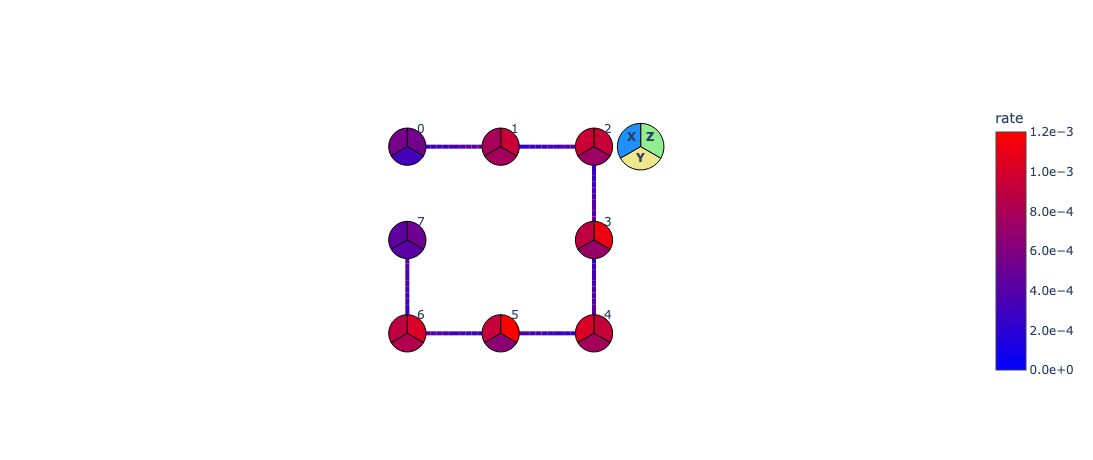

In [4]:
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import PauliList
from qiskit_ibm_runtime.results import LayerError, PauliLindbladError
from qiskit_ibm_runtime.visualization.embeddings import Embedding
from qiskit_noise_learning.aer_executor import AerExecutor
from qiskit_noise_learning.noise_learner import LearningOptions, NoiseLearner
from samplomatic import InjectNoise

line_coupling = [(i, i + 1) for i in range(num_qubits - 1)]
backend = GenericBackendV2(
    num_qubits=num_qubits, basis_gates=["id", "rz", "sx", "x", "cz"], coupling_map=line_coupling
)

# first learn only the layers PEC will inject noise into, i.e. not the measurement layer
pec_layers = [
    layer
    for layer in slc_pec_task.find_unique_layers(mirrored_circuit, slc_boxing_options)
    if get_annotation(layer.operation, InjectNoise)
]
layers = slc_pec_task.find_unique_layers(mirrored_circuit, slc_boxing_options)

learning_options = LearningOptions(
    fragment_depths=[2, 4, 8, 16], num_randomizations=250, shots_per_randomizations=16
)

# qiskit-noise-learning is not compatible with the Executor in local mode,
# and requires the simulator present in the package for running simulation
noise_dict = {
    get_annotation(layer.operation, Tag).ref: noise_layer
    for layer, noise_layer in layer_noise_model
}
noise_learner_simulator = AerExecutor(qasm_simulator=AerSimulator(), noise_dict=noise_dict)
learner = NoiseLearner(backend, options=learning_options, executor=noise_learner_simulator)
learned_noise = learner.run(pec_layers).result().to_dict()  # keyed by InjectNoise reference

# Draw the learned model on the line, laid out as a line with the qubits in order.
# Composing the two layers' maps sums their rates, giving one map over all the edges.
embedding = Embedding(
    [(0, 0), (0, 2), (0, 4), (2, 4), (4, 4), (4, 2), (4, 0), (2, 0)], line_coupling
)
first, second = learned_noise.values()
learned_model = first.compose(second).simplify()
error = PauliLindbladError(
    PauliList(learned_model.get_qubit_sparse_pauli_list_copy().to_pauli_list()), learned_model.rates
)
fig = LayerError(circuit, list(range(num_qubits)), error).draw_map(
    embedding, radius=0.4, height=460, width=620
)
fig.update_traces(
    marker={
        "cmin": 0,
        "cmax": max(learned_model.rates),
        "colorbar": {"tickformat": ".1e", "title": "rate"},
    },
    selector={"mode": "markers"},
)
fig.show()

### Use the learned noise to merge the computed bounds into local scales matrix

With both the classical bounds (from the previous step) and the learned noise rates in hand, we can now compute a *local scales matrix* — a per-error weight that determines how aggressively PEC should cancel each individual noise term.

The key idea of SLC is that not all errors need to be fully cancelled. An error whose forward and backward bounds are both small has a negligible effect on the observable regardless of its rate, so it can be left partially or fully un-mitigated. `compute_local_scales_using_slc` merges the classical bounds with the learned Pauli-Lindblad rates to assign each error a scale between 0 (completely ignored) and 1 (fully cancelled), subject to a user-specified `bias_tolerance`. Errors with a large estimated bias contribution receive a scale close to 1 (full PEC treatment), while errors with a small contribution receive a lower scale, reducing the sampling overhead they carry.

SLC exposes a continuous knob between the two extremes — vanilla PEC (zero bias, highest overhead) and no mitigation at all (zero overhead, full noise bias). The `bias_tolerance` parameter controls this knob: setting it to `0` recovers full PEC, while larger values allow more residual bias in exchange for a lower sampling overhead γ².

This step sweeps `bias_tolerance` across a range of values and computes the resulting sampling overhead for each. Plotting these points against the full-PEC overhead helps you choose a working point that fits your shot budget. For example, tolerating a 5 % residual bias may reduce the sampling overhead by an order of magnitude compared with full PEC, making the computation feasible on today's QPUs where it would otherwise not be.

Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.
Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.


Text(0.5, 0.98, 'PEC sampling overhead reduction due to SLC')

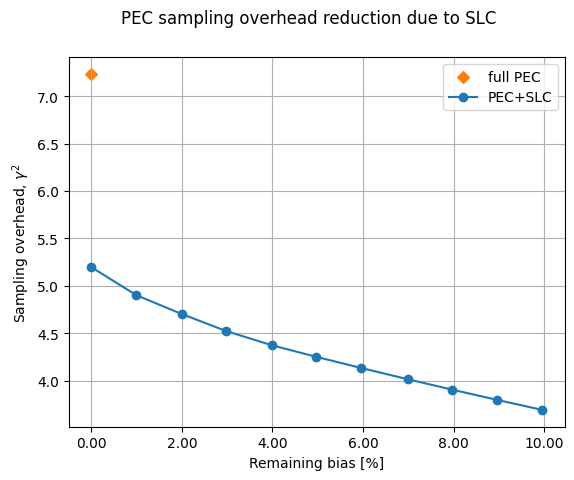

In [5]:
import matplotlib.pyplot as plt

biases = []
costs = []
for bias in [0.0, *np.arange(0.01, 0.11, 0.01).tolist()]:
    _, cost_, bias_ = slc_pec_task.compute_local_scales_using_slc(
        learned_noise, bias_tolerance=bias
    )
    biases.append(bias_)
    costs.append(cost_)

# Compute tha full PEC overhead and compare it with the overhead and bias of different SLC configurations
vanilla_gamma = slc_pec_task.calculate_gamma(slc_pec_task.boxed_circuit, learned_noise, 1)

xticks = np.arange(0, 11, 2)

fig, ax = plt.subplots()
ax.scatter([0], [vanilla_gamma**2], marker="D", c="tab:orange", label="full PEC")
ax.plot(
    100 * np.array(biases),
    np.array(costs),
    "o-",
    c="tab:blue",
    label="PEC+SLC",
)
ax.set_xticks(xticks, [f"{x:.2f}" for x in xticks])

ax.set_xlabel("Remaining bias [%]")
ax.set_ylabel(r"Sampling overhead, $\gamma^2$")
ax.grid()
ax.legend()
fig.suptitle("PEC sampling overhead reduction due to SLC")

### Choose desired bias bound based on shot overhead-bias trade-off

In this guide we choose a bias tolerance of 5%. Note that this bias calculation is based on the learned noise model, which might not be perfectly aligned with the real noise of the device.

Using `draw_shaded_lightcone` function from the `qiskit_addon_slc` packagem, we show for each Pauli type (X, Y, Z), which parts of the circuit sit inside the effective lightcone of the observable and therefore receive significant mitigation weight (light pixels), and which sit outside and are assigned a low scale (dark pixels).

Optimal spacetime partitioning not implemented! Just partitioning list of noisy boxes.


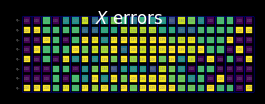

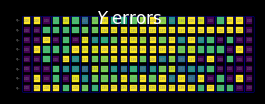

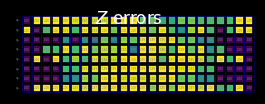

In [6]:
import IPython.display
from qiskit_addon_slc.visualization import draw_shaded_lightcone

chosen_bias_threshold = 0.05
local_scales, sampling_cost, bias = slc_pec_task.compute_local_scales_using_slc(
    learned_noise, bias_tolerance=chosen_bias_threshold
)

for p in "XYZ":
    IPython.display.display(
        draw_shaded_lightcone(
            slc_pec_task.boxed_circuit,
            slc_pec_task._slc_merged_bounds,
            {key: value.get_qubit_sparse_pauli_list_copy() for key, value in learned_noise.items()},
            pauli_filter=p,
            scale=0.15,
            fold=-1,
            idle_wires=False,
            measure_arrows=False,
        )
    )

### Prepare a PEC + SLC program, execute the program, and post-process

With the local scales chosen, we can build the full PEC+SLC execution program. The `PEC.prepare` call constructs a `QuantumProgram` that encodes the anti-noise injection strategy into the circuit's box annotations. Passing `noise_gain="slc_local_scales"` instructs the executor to use the per-error weights computed by `compute_local_scales_using_slc`, rather than applying the same full inverse-noise gain to every error as vanilla PEC would.

To produce a fair comparison, a second `PEC` task is prepared with `noise_gain=0`, which corresponds to full PEC cancellation with no SLC bias allowance. Both programs are added to the same `QuantumProgram` so they share a single execution job — their circuits are interleaved and executed together, meaning any hardware drift affects both equally.

After the job completes, `postprocess` converts the raw measurement bitstrings into expectation values, applying the appropriate PEC rescaling factor γ for each task.

In [7]:
program_pec = slc_pec_task.prepare(
    circuit=mirrored_circuit,
    observables=[observable],
    parameters=None,
    num_randomizations=num_randomizations,
    shots_per_randomization=shots_per_randomization,
    custom_boxing_options=slc_boxing_options,
    noise_maps=learned_noise,  # PEC option
    noise_gain="slc_local_scales",  # PEC option. Defines the usage of SLC
    max_sampling_overhead=100,  # PEC option
)

full_pec_task = PEC()
program_pec = full_pec_task.prepare(
    circuit=mirrored_circuit,
    observables=[observable],
    parameters=None,
    num_randomizations=num_randomizations,
    shots_per_randomization=shots_per_randomization,
    custom_boxing_options=boxing_options,
    quantum_program=program_pec,
    noise_maps=learned_noise,  # PEC option
    noise_gain=0,  # PEC option
    max_sampling_overhead=100,  # PEC option
)

# Execute
program_pec._semantic_role = "simulation"  # flag the program for the simulator
job_pec_results = noisy_executor.run(program_pec).result()

# post-processing
pec_slc_res = slc_pec_task.postprocess(job_pec_results)
full_pec_res = full_pec_task.postprocess(job_pec_results)

### Compare the mitigated expectation values and shot overhead

The ideal expectation value of the mirrored circuit is 1 by construction, so the bias of any estimate is simply `|1 - result|`. This final cell prints the bias and total shot count for three scenarios side-by-side:

- **Unmitigated**: the raw noisy expectation value with no error cancellation applied.
- **Full PEC**: zero-bias error cancellation using the complete inverse noise model on every layer, at the full γ² sampling overhead.
- **PEC+SLC**: error cancellation guided by the shaded-lightcone local scales, tolerating the chosen `bias_tolerance` in exchange for a substantially lower shot count.

Comparing the three rows shows the concrete benefit of SLC: the mitigated bias of PEC+SLC stays well below the unmitigated bias while the total number of shots is significantly smaller than what full PEC required.

In [8]:
print(
    f"Unmitigated result bais: {np.abs(1 - unmitigated_res.data.evs[0]) * 100:.2f}%, \
total shots ran: {job_unmit_res[0]['_meas'].shape[0] * job_unmit_res[0]['_meas'].shape[2]}"
)

print(
    f"Full PEC final result bais: {np.abs(1 - full_pec_res.data.evs[0]) * 100:.2f}%, \
total shots ran: {job_pec_results[1]['_meas'].shape[0] * job_pec_results[1]['_meas'].shape[2]}"
)

print(
    f"PEC+SLC final result bais: {np.abs(1 - pec_slc_res.data.evs[0]) * 100:.2f}%, \
total shots ran: {job_pec_results[0]['_meas'].shape[0] * job_pec_results[0]['_meas'].shape[2]}"
)

Unmitigated result bais: 36.88%, total shots ran: 6400
Full PEC final result bais: 1.58%, total shots ran: 46320
PEC+SLC final result bais: 6.06%, total shots ran: 27216
